# Modelos básicos · Generalização entre eletrodos

Comparamos regressão logística, KNN, Random Forest, Gaussian Naive Bayes, LDA e SISSO com SVM linear para classificação de VEs de MCF10A e HCC1806 em 49 aplicações históricas de nove eletrodos. Na avaliação **LOEO** (*leave-one-electrode-out*), todas as aplicações do eletrodo avaliado ficam fora do ajuste. Cada aplicação física contribui com uma previsão. O resultado em LOO (uma aplicação excluída) aparece na tabela como referência adicional.

As concentrações variam entre dispositivos e campanhas, e a comparação é exploratória.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneGroupOut, LeaveOneOut
from sklearn.naive_bayes import GaussianNB

PASTA = Path.cwd()
if (PASTA / 'TCC_EIS_Modelos_Basicos').is_dir():
    PASTA = PASTA / 'TCC_EIS_Modelos_Basicos'
assert (PASTA / 'dados').is_dir(), 'Abra o notebook na pasta do projeto ou do pacote.'
sys.path.insert(0, str(PASTA))
from dados_dispositivos import carregar_recorte
from modelos_basicos import basic_models, cv_predictions

PASTA_FIGURAS = PASTA.parent / 'imagens_prontas'
PASTA_FIGURAS.mkdir(exist_ok=True)
plt.rcParams.update({
    'font.family': 'Times New Roman', 'pdf.fonttype': 42,
    'figure.dpi': 120, 'font.size': 11, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'legend.fontsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'grid.color': '#D8DEE3', 'grid.alpha': .7, 'axes.edgecolor': '#ABB5BD',
    'figure.constrained_layout.use': True,
})
print(f'scikit-learn {sklearn.__version__}')

scikit-learn 1.9.1


## Recorte de aplicações com identificação conhecida

A linhagem vem do primeiro identificador de linhagem no nome do arquivo. No E09, B03 e B10 são MCF10A. Os trechos pre_HCC e pos_HCC informam a sequência do experimento.

In [2]:
df, X = carregar_recorte(PASTA / 'dados' / 'Medicoes_EIS_Por_Dispositivo_ATUALIZADO_E02.zip')
display(pd.crosstab(df.electrode, df.classe, margins=True))

classe,HCC1806,MCF10A,All
electrode,,,
E01,2,2,4
E03,2,2,4
E04,2,2,4
E05,2,2,4
E07,9,9,18
E09,1,2,3
E10,2,2,4
E13,2,2,4
E14,2,2,4


## Seis atributos espectrais de 1 Hz a 1 MHz

Primeiro calculamos a média de |Z| das leituras da mesma aplicação em cada frequência. Depois calculamos a média do logaritmo decimal do módulo por banda. Os modelos recebem os mesmos atributos. O ajuste e as transformações que dependem dos dados são refeitos dentro de cada treino.

In [3]:
y = df.classe.eq('HCC1806').astype(int).to_numpy()
groups = df.electrode.to_numpy()
print('Matriz:', X.shape, '| Contagem por classe:', np.bincount(y))

Matriz: (49, 6) | Contagem por classe: [25 24]


## Avaliação por eletrodo excluído

A tabela inclui LOEO e LOO para os modelos básicos. O mapa mostra acertos sobre o total de aplicações de cada eletrodo. O SISSO 3.0.2 com SVM linear entra na comparação LOEO quando as previsões do notebook 04 estão disponíveis.

In [4]:
modelos_basicos = basic_models()
modelos = {nome: modelos_basicos[nome] for nome in ('Regressão logística', 'KNN (k=5)', 'Random Forest')}
modelos['Gaussian Naive Bayes'] = GaussianNB()
modelos['LDA'] = LinearDiscriminantAnalysis()
linhas, por_eletrodo = [], []
for nome, modelo in modelos.items():
    for validacao, divisor, grupos in [
        ('LOEO', LeaveOneGroupOut(), groups),
        ('LOO', LeaveOneOut(), None),
    ]:
        pred = cv_predictions(X, y, divisor, groups=grupos, model=modelo)
        acertou = pred == y
        linhas.append((nome, validacao, acertou.sum(), len(y), acertou.mean()))
        if validacao == 'LOEO':
            por_eletrodo.append(pd.DataFrame({'Modelo': nome, 'Eletrodo': groups, 'Correto': acertou}))

arquivo_sisso = PASTA / 'dados' / 'previsoes_sisso_loeo.csv'
if arquivo_sisso.is_file():
    previsoes = pd.read_csv(arquivo_sisso).set_index('application', verify_integrity=True)
    assert set(previsoes.index) == set(df.application)
    previsoes = previsoes.loc[df.application]
    assert np.array_equal(previsoes.electrode.to_numpy(), groups)
    assert np.array_equal(previsoes.classe.to_numpy(), df.classe.to_numpy())
    assert previsoes.previsao.isin(['MCF10A', 'HCC1806']).all()
    acertou = previsoes.previsao.eq(previsoes.classe).to_numpy()
    nome = 'SISSO 3.0.2 + SVM linear'
    linhas.append((nome, 'LOEO', acertou.sum(), len(y), acertou.mean()))
    por_eletrodo.append(pd.DataFrame({'Modelo': nome, 'Eletrodo': groups, 'Correto': acertou}))

resultados = pd.DataFrame(linhas, columns=['Modelo', 'Validação', 'Acertos', 'Total', 'Acurácia'])
por_eletrodo = (pd.concat(por_eletrodo).groupby(['Modelo', 'Eletrodo']).Correto
                .agg(Acertos='sum', Total='size'))
display(resultados.assign(Acurácia=resultados.Acurácia.map('{:.1%}'.format)))

C:\Users\pedro\AppData\Local\Temp\ipykernel_47016\2164006873.py:19: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  previsoes = pd.read_csv(arquivo_sisso).set_index('application', verify_integrity=True)


,Modelo,Validação,Acertos,Total,Acurácia
0,Regressão logística,LOEO,26,49,53.1%
1,Regressão logística,LOO,10,49,20.4%
2,KNN (k=5),LOEO,26,49,53.1%
3,KNN (k=5),LOO,18,49,36.7%
4,Random Forest,LOEO,27,49,55.1%
5,Random Forest,LOO,15,49,30.6%
6,Gaussian Naive Bayes,LOEO,26,49,53.1%
7,Gaussian Naive Bayes,LOO,17,49,34.7%
8,LDA,LOEO,26,49,53.1%
9,LDA,LOO,18,49,36.7%


## Transferência geral e por dispositivo

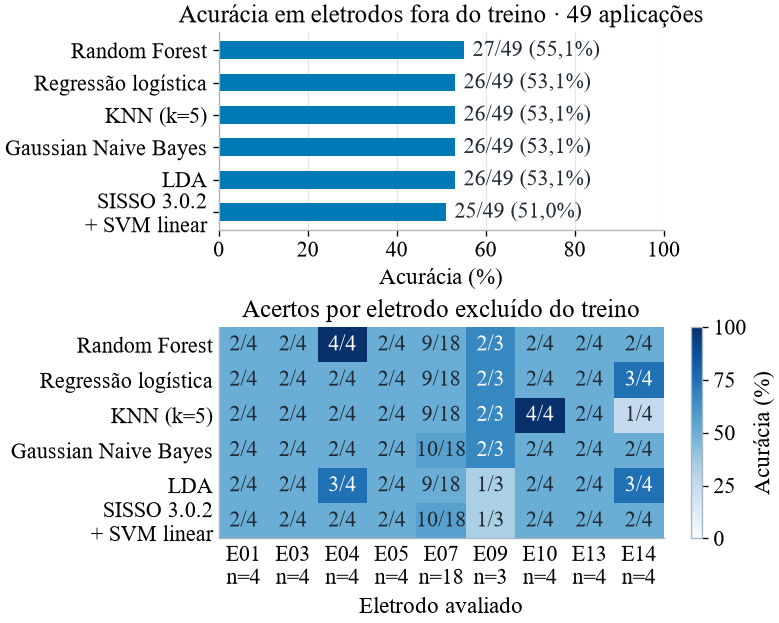

Eletrodo,E01,E03,E04,E05,E07,E09,E10,E13,E14
Modelo,,,,,,,,,
Random Forest,2/4,2/4,4/4,2/4,9/18,2/3,2/4,2/4,2/4
Regressão logística,2/4,2/4,2/4,2/4,9/18,2/3,2/4,2/4,3/4
KNN (k=5),2/4,2/4,2/4,2/4,9/18,2/3,4/4,2/4,1/4
Gaussian Naive Bayes,2/4,2/4,2/4,2/4,10/18,2/3,2/4,2/4,2/4
LDA,2/4,2/4,3/4,2/4,9/18,1/3,2/4,2/4,3/4
SISSO 3.0.2 + SVM linear,2/4,2/4,2/4,2/4,10/18,1/3,2/4,2/4,2/4


In [5]:
loeo = resultados[resultados['Validação'].eq('LOEO')].sort_values(
    'Acurácia', ascending=False, kind='stable',
)
nomes = loeo.Modelo.to_list()
eletrodos = sorted(set(groups))
acertos = por_eletrodo.Acertos.unstack().loc[nomes, eletrodos]
totais = por_eletrodo.Total.unstack().loc[nomes, eletrodos]
assert np.array_equal(acertos.sum(axis=1).to_numpy(), loeo.Acertos.to_numpy())
assert totais.sum(axis=1).eq(len(y)).all()
acuracia = acertos / totais

with plt.rc_context({'font.size': 13, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'axes.labelsize': 14, 'axes.titlesize': 15, 'figure.labelsize': 14,
                     'legend.fontsize': 13, 'legend.title_fontsize': 15}):
    rotulos = {
        'SISSO 3.0.2 + SVM linear': 'SISSO 3.0.2\n+ SVM linear',
    }
    rotulos_visiveis = [rotulos.get(nome, nome) for nome in nomes]

    fig, (ax, ax_mapa) = plt.subplots(2, 1, figsize=(16.5 / 2.54, 13.2 / 2.54),
                                      gridspec_kw={'height_ratios': [1, 1.07]})
    posicoes = np.arange(len(nomes))
    ax.barh(posicoes, 100 * loeo.Acurácia, color='#0079B7', height=.55)
    for pos, r in enumerate(loeo.itertuples(index=False)):
        percentual = f'{100 * r.Acurácia:.1f}'.replace('.', ',')
        ax.text(100 * r.Acurácia + 2, pos, f'{r.Acertos}/{r.Total} ({percentual}%)',
                va='center', color='#202934')
    ax.set_yticks(posicoes, rotulos_visiveis)
    ax.set(xlim=(0, 100), xlabel='Acurácia (%)',
           title=f'Acurácia em eletrodos fora do treino · {len(y)} aplicações')
    ax.invert_yaxis()
    ax.grid(axis='x')

    cores = ax_mapa.imshow(acuracia, cmap='Blues', vmin=0, vmax=1, aspect='auto',
                           interpolation='nearest')
    n_app = totais.iloc[0]
    ax_mapa.set_xticks(range(len(eletrodos)), [f'{e}\nn={n_app[e]}' for e in eletrodos])
    ax_mapa.set_yticks(posicoes, rotulos_visiveis)
    for i, modelo in enumerate(nomes):
        for j, eletrodo in enumerate(eletrodos):
            total = totais.at[modelo, eletrodo]
            valor = acertos.at[modelo, eletrodo]
            ax_mapa.text(j, i, f'{valor}/{total}', ha='center', va='center',
                         color='white' if valor / total >= .65 else '#202934')
    ax_mapa.tick_params(length=0)
    ax_mapa.set(title='Acertos por eletrodo excluído do treino', xlabel='Eletrodo avaliado')
    escala = fig.colorbar(cores, ax=ax_mapa, ticks=np.linspace(0, 1, 5),
                         label='Acurácia (%)', fraction=.047, pad=.025)
    escala.ax.set_yticklabels(['0', '25', '50', '75', '100'])
    fig.savefig(PASTA_FIGURAS / 'generalizacao_entre_eletrodos.pdf')
    plt.show()
    display(acertos.astype(str) + '/' + totais.astype(str))

## Leitura para o TCC

A avaliação LOEO verifica a transferência para um dispositivo inteiramente excluído do treino. O mapa mostra a variação entre eletrodos e o número de aplicações de cada um. As diferenças entre modelos são descritivas neste conjunto, que reúne campanhas e concentrações distintas. A etapa seguinte examina a classificação dentro de um único eletrodo, o E7.

Com os atributos e rótulos desta análise, o Gaussian Naive Bayes acertou 26/49 em LOEO (53,1%).